# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 12)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [9]:

# ============================================
# CELDA 1: IMPORTACIONES Y CONFIGURACIÓN
# ============================================

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd

# División de datos
from sklearn.model_selection import train_test_split

# Preprocesamiento
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Modelos de clasificación y regresión
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    mean_absolute_error
)

print("Importaciones completadas correctamente.")


Importaciones completadas correctamente.


Esta celda prepara todas las herramientas necesarias para desarrollar el proyecto. Todavía no carga los datos ni entrena modelos, únicamente importa las funciones que utilizarás en las siguientes celdas.

In [10]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


Esta celda carga los datos originales y permite comprobar su tamaño. Todavía no limpia ni combina las tablas, y tampoco entrena ningún modelo.

## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [11]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

Esta celda combina la información de los productos y vendedores, calcula características de cada pedido y crea un resumen con una sola fila por pedido. Esto es necesario porque un pedido puede contener varios productos o vendedores.

In [12]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


Esta celda transforma varias tablas de Olist en una única tabla de pedidos, agrega información de pagos y verifica que cada pedido aparezca una sola vez.

In [13]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


Esta celda limpia los datos, crea la variable que indica si un pedido llegó tarde y calcula nuevas características que utilizará el modelo de Machine Learning.

### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [14]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


Esta celda selecciona y organiza las 28 variables predictoras que utilizará el modelo para anticipar si un pedido llegará tarde, y verifica que los datos cumplan unas condiciones mínimas.

### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [15]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 23
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 23 | Semilla: 1023
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 5f854bc76c68


Esta celda selecciona tu muestra individual de 35.000 pedidos y los divide en entrenamiento, validación y prueba. Además, registra tu ID y genera una huella para comprobar que la muestra sea reproducible.

## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [16]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


Esta celda realiza dos tareas importantes: prepara las variables para los modelos de Machine Learning y construye un modelo de referencia para comparar su rendimiento con modelos más avanzados.

### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [20]:

peso_clases = None

modelo = make_pipeline(
    preprocesamiento,
    LogisticRegression(
        class_weight=peso_clases,
        max_iter=1000,
        random_state=1023
    )
)

modelo.fit(X_train, y_train)

pred = modelo.predict(X_valid)
prob = modelo.predict_proba(X_valid)[:, 1]

print("Modelo: Sin balanceo")
print("Accuracy:", round(accuracy_score(y_valid, pred), 3))
print("Precision:", round(precision_score(y_valid, pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_valid, pred, zero_division=0), 3))
print("F1:", round(f1_score(y_valid, pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_valid, prob), 3))
print("Average Precision:", round(average_precision_score(y_valid, prob), 3))


Modelo: Sin balanceo
Accuracy: 0.932
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.681
Average Precision: 0.145


In [21]:

peso_clases = 'balanced'

modelo = make_pipeline(
    preprocesamiento,
    LogisticRegression(
        class_weight=peso_clases,
        max_iter=1000,
        random_state=1023
    )
)

modelo.fit(X_train, y_train)

pred = modelo.predict(X_valid)
prob = modelo.predict_proba(X_valid)[:, 1]

print("Modelo: Balanced")
print("Accuracy:", round(accuracy_score(y_valid, pred), 3))
print("Precision:", round(precision_score(y_valid, pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_valid, pred), 3))
print("F1:", round(f1_score(y_valid, pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_valid, prob), 3))
print("Average Precision:", round(average_precision_score(y_valid, prob), 3))


Modelo: Balanced
Accuracy: 0.656
Precision: 0.112
Recall: 0.592
F1: 0.189
ROC-AUC: 0.683
Average Precision: 0.141


**¿Qué significa cada resultado?**

**Accuracy: exactitud general**
- Sin balanceo: 93,2 %.
- Con balanceo: 65,6 %.
El primero parece mejor, pero hay una trampa: si la mayoría de los pedidos no son tardíos, el modelo puede acertar mucho prediciendo siempre que llegarán a tiempo.




**Recall: detección de pedidos tardíos**
- Sin balanceo: 0 %.
- Con balanceo: 59,2 %.
Este es uno de los cambios más importantes. El modelo sin balanceo no detectó pedidos tardíos; el balanceado identifica aproximadamente 59 de cada 100 pedidos que realmente llegan tarde.




**Precision: fiabilidad de las alertas**
- Sin balanceo: 0 %.
- Con balanceo: 11,2 %.
De cada 100 pedidos que el modelo balanceado marca como tardíos, aproximadamente 11 realmente son tardíos y 89 son alertas incorrectas. Por eso, aunque detecta más retrasos, también genera bastantes falsas alarmas.




**F1: equilibrio entre precision y recall**
- Sin balanceo: 0.
- Con balanceo: 0,189.
El modelo balanceado obtiene un resultado positivo porque consigue detectar pedidos tardíos, aunque todavía tiene dificultades para hacerlo con precisión.




**ROC-AUC: capacidad de distinguir las clases**
- Sin balanceo: 0,681.
- Con balanceo: 0,683.
Ambos son muy parecidos. Esto indica que el balanceo cambia bastante las predicciones finales, pero no mejora sustancialmente la capacidad general de ordenar los pedidos según su riesgo de retraso.




**Average Precision: identificación de la clase tardía**
- Sin balanceo: 0,145.
- Con balanceo: 0,141.
Los valores son similares y relativamente bajos. El modelo todavía tiene dificultades para identificar de manera fiable los pedidos tardíos.



**¿Cuál modelo es mejor?**

Para el objetivo de detectar pedidos que podrían llegar tarde, el modelo balanced es más útil como punto de partida, porque el modelo sin balanceo no detectó ninguno.

Sin embargo, no significa que balanced sea definitivamente el mejor. La precisión de 11,2 % implica muchas alertas incorrectas. Además, el Average Precision es ligeramente menor. Debemos tener en cuenta el coste de los errores que establece la actividad.


**Comparación de regresión logística con y sin balanceo**

El modelo sin balanceo obtuvo una exactitud de 93,2 %, pero presentó un recall, una precisión y un F1 de cero, lo que indica que no identificó pedidos tardíos. Por tanto, su alta exactitud resulta engañosa debido al desbalance de las clases.

Por otro lado, el modelo con `class_weight='balanced'` obtuvo un recall de 59,2 % y un F1 de 0,189. Esto demuestra que logró detectar una proporción importante de los pedidos tardíos, aunque su precisión de 11,2 % indica que generó numerosas falsas alarmas.

Los valores de ROC-AUC fueron similares (0,681 y 0,683), al igual que Average Precision (0,145 y 0,141). En conclusión, el modelo balanceado es un mejor punto de partida para detectar retrasos, pero requiere evaluar los costes de los falsos positivos y falsos negativos antes de tomar una decisión definitiva.

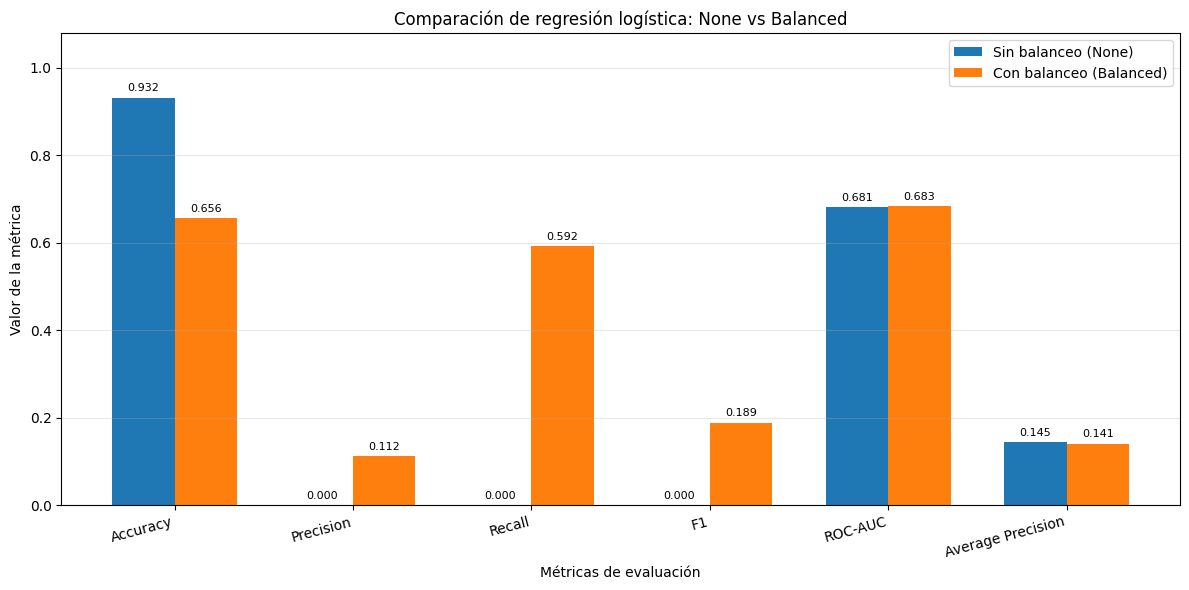

In [22]:

import matplotlib.pyplot as plt
import numpy as np

# Métricas obtenidas de tus dos modelos
metricas = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'Average Precision']

sin_balanceo = [0.932, 0.000, 0.000, 0.000, 0.681, 0.145]
con_balanceo = [0.656, 0.112, 0.592, 0.189, 0.683, 0.141]

# Posición de las barras
x = np.arange(len(metricas))
ancho = 0.35

# Crear gráfica
fig, ax = plt.subplots(figsize=(12, 6))

barras1 = ax.bar(
    x - ancho/2,
    sin_balanceo,
    ancho,
    label='Sin balanceo (None)'
)

barras2 = ax.bar(
    x + ancho/2,
    con_balanceo,
    ancho,
    label='Con balanceo (Balanced)'
)

# Títulos y etiquetas
ax.set_title('Comparación de regresión logística: None vs Balanced')
ax.set_ylabel('Valor de la métrica')
ax.set_xlabel('Métricas de evaluación')
ax.set_xticks(x)
ax.set_xticklabels(metricas, rotation=15, ha='right')
ax.set_ylim(0, 1.08)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Mostrar valores sobre las barras
ax.bar_label(barras1, fmt='%.3f', padding=3, fontsize=8)
ax.bar_label(barras2, fmt='%.3f', padding=3, fontsize=8)

plt.tight_layout()
plt.show()


## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

In [23]:

# TODO 2. Métricas y matrices de confusión para ambos modelos

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
import pandas as pd

# Guardar los modelos entrenados anteriormente
modelos_evaluar = {
    'Sin balanceo (None)': modelos['Sin balanceo']
        if 'modelos' in globals() and 'Sin balanceo' in modelos
        else None,
    'Con balanceo (Balanced)': modelos['Balanced']
        if 'modelos' in globals() and 'Balanced' in modelos
        else None
}

# Si entrenaste los modelos en celdas separadas,
# guarda cada uno antes de volver a entrenar el segundo.


In [24]:

from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)
import pandas as pd

# Entrenar y guardar ambos modelos
modelo_none = make_pipeline(
    preprocesamiento,
    LogisticRegression(class_weight=None, max_iter=1000, random_state=1023)
)
modelo_none.fit(X_train, y_train)

modelo_balanced = make_pipeline(
    preprocesamiento,
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=1023)
)
modelo_balanced.fit(X_train, y_train)

# Evaluar ambos en validación
resultados = {}
matrices_confusion = {}

for nombre, modelo_eval in {
    'Sin balanceo': modelo_none,
    'Balanced': modelo_balanced
}.items():
    pred_eval = modelo_eval.predict(X_valid)
    proba = modelo_eval.predict_proba(X_valid)[:, 1]

    resultados[nombre] = {
        'accuracy': accuracy_score(y_valid, pred_eval),
        'precision': precision_score(y_valid, pred_eval, zero_division=0),
        'recall': recall_score(y_valid, pred_eval, zero_division=0),
        'f1': f1_score(y_valid, pred_eval, zero_division=0),
        'roc_auc': roc_auc_score(y_valid, proba),
        'ap': average_precision_score(y_valid, proba)
    }

    matrices_confusion[nombre] = confusion_matrix(y_valid, pred_eval)

# Mostrar métricas comparativas
medidas_comparativas = pd.DataFrame(resultados).T
display(medidas_comparativas.round(3))

# Mostrar matrices de confusión
for nombre, matriz in matrices_confusion.items():
    print(f'\nMatriz de confusión: {nombre}')
    print('Filas = clase real [0, 1]; columnas = predicción [0, 1]')
    print(matriz)

# Conservar las variables que pide la guía para el modelo balanceado
modelo = modelo_balanced
pred = modelo.predict(X_valid)
proba = modelo.predict_proba(X_valid)[:, 1]

medidas = resultados['Balanced']


,accuracy,precision,recall,f1,roc_auc,ap
Sin balanceo,0.932,0.000,0.000,0.000,0.681,0.145
Balanced,0.656,0.112,0.592,0.189,0.683,0.141



Matriz de confusión: Sin balanceo
Filas = clase real [0, 1]; columnas = predicción [0, 1]
[[4895    0]
 [ 355    0]]

Matriz de confusión: Balanced
Filas = clase real [0, 1]; columnas = predicción [0, 1]
[[3235 1660]
 [ 145  210]]


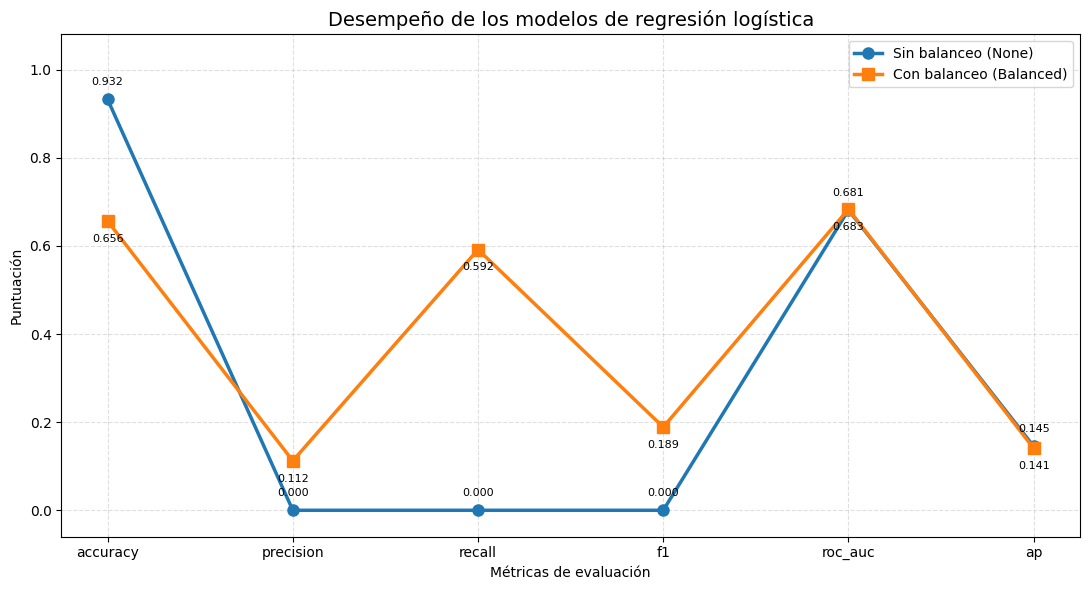

In [25]:

import matplotlib.pyplot as plt
import numpy as np

# Métricas de los dos modelos
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'ap']

sin_balanceo = medidas_comparativas.loc['Sin balanceo', metricas].values
balanceado = medidas_comparativas.loc['Balanced', metricas].values

# Crear gráfica de líneas
plt.figure(figsize=(11, 6))

plt.plot(
    metricas, sin_balanceo,
    marker='o', linewidth=2.5, markersize=8,
    label='Sin balanceo (None)'
)

plt.plot(
    metricas, balanceado,
    marker='s', linewidth=2.5, markersize=8,
    label='Con balanceo (Balanced)'
)

# Mostrar valores junto a cada punto
for i, valor in enumerate(sin_balanceo):
    plt.annotate(
        f'{valor:.3f}', (i, valor),
        xytext=(0, 10), textcoords='offset points',
        ha='center', fontsize=8
    )

for i, valor in enumerate(balanceado):
    plt.annotate(
        f'{valor:.3f}', (i, valor),
        xytext=(0, -15), textcoords='offset points',
        ha='center', fontsize=8
    )

plt.title('Desempeño de los modelos de regresión logística', fontsize=14)
plt.xlabel('Métricas de evaluación')
plt.ylabel('Puntuación')
plt.ylim(-0.06, 1.08)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [26]:

import pandas as pd
import matplotlib.pyplot as plt

# Preparar los datos de validación
analisis_none = valid.copy()
analisis_balanced = valid.copy()

# Generar predicciones de ambos modelos
analisis_none['pred'] = modelo_none.predict(X_valid)
analisis_balanced['pred'] = modelo_balanced.predict(X_valid)

# Marcar los errores: predicción diferente al valor real
analisis_none['error'] = (
    analisis_none['is_late'] != analisis_none['pred']
).astype(int)

analisis_balanced['error'] = (
    analisis_balanced['is_late'] != analisis_balanced['pred']
).astype(int)

analisis_none['Modelo'] = 'Sin balanceo (None)'
analisis_balanced['Modelo'] = 'Con balanceo (Balanced)'

# Unir los resultados
analisis_completo = pd.concat(
    [analisis_none, analisis_balanced],
    ignore_index=True
)

# Agrupar por mes de compra y modelo
errores_mes = (
    analisis_completo
    .groupby(['Modelo', 'mes_compra'], as_index=False)
    .agg(
        pedidos=('error', 'size'),
        errores=('error', 'sum'),
        tasa_error=('error', 'mean')
    )
)
errores_mes['porcentaje_error'] = errores_mes['tasa_error'] * 100

print("COMPARACIÓN POR MES DE COMPRA")
display(
    errores_mes[
        ['Modelo', 'mes_compra', 'pedidos', 'errores', 'porcentaje_error']
    ].round(2)
)

# Agrupar por estado del cliente y modelo
errores_estado = (
    analisis_completo
    .groupby(['Modelo', 'customer_state'], as_index=False)
    .agg(
        pedidos=('error', 'size'),
        errores=('error', 'sum'),
        tasa_error=('error', 'mean')
    )
)
errores_estado['porcentaje_error'] = errores_estado['tasa_error'] * 100

print("COMPARACIÓN POR ESTADO DEL CLIENTE")
display(
    errores_estado[
        ['Modelo', 'customer_state', 'pedidos', 'errores', 'porcentaje_error']
    ].round(2)
)


COMPARACIÓN POR MES DE COMPRA


,Modelo,mes_compra,pedidos,errores,porcentaje_error
0,Con balanceo (Balanced),1,419,146,34.84
1,Con balanceo (Balanced),2,482,172,35.68
2,Con balanceo (Balanced),3,487,212,43.53
3,Con balanceo (Balanced),4,520,179,34.42
4,Con balanceo (Balanced),5,544,188,34.56
5,Con balanceo (Balanced),6,515,137,26.60
6,Con balanceo (Balanced),7,564,246,43.62
7,Con balanceo (Balanced),8,534,244,45.69
8,Con balanceo (Balanced),9,210,73,34.76
9,Con balanceo (Balanced),10,259,63,24.32


COMPARACIÓN POR ESTADO DEL CLIENTE


,Modelo,customer_state,pedidos,errores,porcentaje_error
0,Con balanceo (Balanced),AC,3,0,0.00
1,Con balanceo (Balanced),AL,16,12,75.00
2,Con balanceo (Balanced),AM,2,1,50.00
3,Con balanceo (Balanced),AP,2,0,0.00
4,Con balanceo (Balanced),BA,197,135,68.53
5,Con balanceo (Balanced),CE,68,53,77.94
6,Con balanceo (Balanced),DF,131,55,41.98
7,Con balanceo (Balanced),ES,106,54,50.94
8,Con balanceo (Balanced),GO,99,37,37.37
9,Con balanceo (Balanced),MA,40,30,75.00


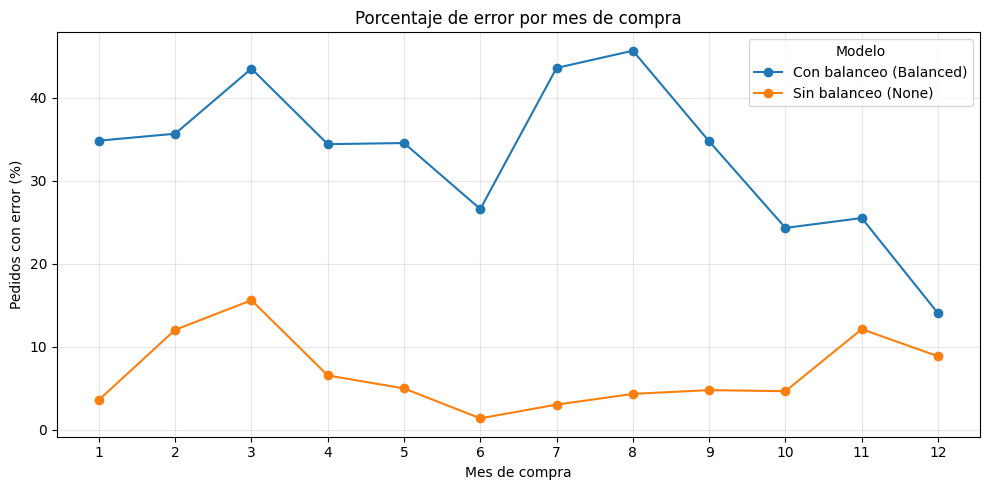

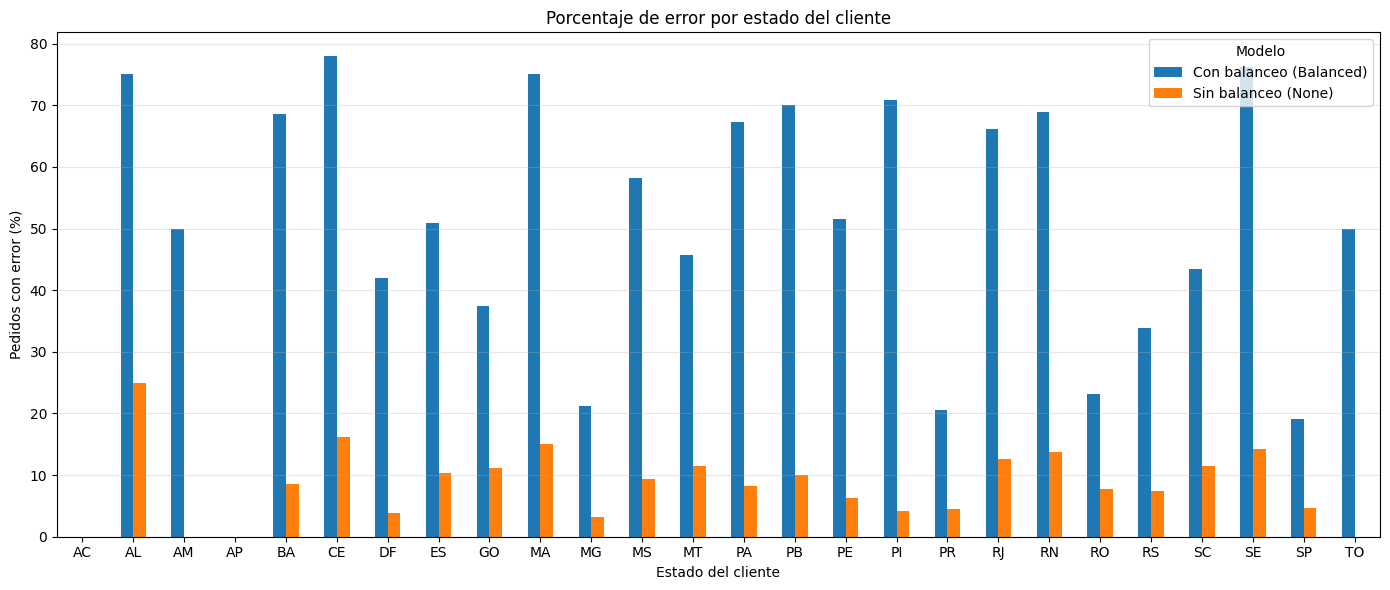

In [27]:

# Gráfica 1: porcentaje de error por mes
tabla_mes = errores_mes.pivot(
    index='mes_compra',
    columns='Modelo',
    values='porcentaje_error'
)

tabla_mes.plot(kind='line', marker='o', figsize=(10, 5))
plt.title('Porcentaje de error por mes de compra')
plt.xlabel('Mes de compra')
plt.ylabel('Pedidos con error (%)')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.legend(title='Modelo')
plt.tight_layout()
plt.show()


# Gráfica 2: porcentaje de error por estado
tabla_estado = errores_estado.pivot(
    index='customer_state',
    columns='Modelo',
    values='porcentaje_error'
)

tabla_estado.plot(kind='bar', figsize=(14, 6))
plt.title('Porcentaje de error por estado del cliente')
plt.xlabel('Estado del cliente')
plt.ylabel('Pedidos con error (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Modelo')
plt.tight_layout()
plt.show()


### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [28]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Costos establecidos en la actividad
COSTO_FP = 8
COSTO_FN = 35

# Evaluar ambos modelos sobre los mismos datos de validación
modelos_evaluar = {
    'Sin balanceo (None)': modelo_none,
    'Con balanceo (Balanced)': modelo_balanced
}

resultados_costos = []

for nombre, modelo_eval in modelos_evaluar.items():

    # Obtener predicciones
    predicciones = modelo_eval.predict(X_valid)

    # Matriz de confusión: TN, FP, FN, TP
    tn, fp, fn, tp = confusion_matrix(
        y_valid, predicciones, labels=[0, 1]
    ).ravel()

    # Calcular costo empresarial
    costo_fp_fn = (fp * COSTO_FP) + (fn * COSTO_FN)

    resultados_costos.append({
        'Modelo': nombre,
        'Verdaderos negativos': tn,
        'Falsos positivos': fp,
        'Falsos negativos': fn,
        'Verdaderos positivos': tp,
        'Costo falsos positivos (R$)': fp * COSTO_FP,
        'Costo falsos negativos (R$)': fn * COSTO_FN,
        'Costo total (R$)': costo_fp_fn
    })

# Mostrar comparación
comparacion_costos = pd.DataFrame(resultados_costos)
display(comparacion_costos)



,Modelo,Verdaderos negativos,Falsos positivos,Falsos negativos,Verdaderos positivos,Costo falsos positivos (R$),Costo falsos negativos (R$),Costo total (R$)
0,Sin balanceo (None),4895,0,355,0,0,12425,12425
1,Con balanceo (Balanced),3235,1660,145,210,13280,5075,18355


### Interpretación del costo empresarial

Al evaluar los modelos con un costo de R$ 8 por falso positivo y R$ 35 por falso negativo, el modelo sin balanceo presentó un costo total de R$ 12.425, mientras que el modelo con `class_weight='balanced'` obtuvo un costo de R$ 18.355.

Aunque el modelo balanceado detecta una mayor cantidad de pedidos tardíos, genera más falsos positivos, lo que incrementa el costo empresarial total. Por lo tanto, según los costos definidos en esta actividad, el modelo sin balanceo resulta más económico en el conjunto de validación. Sin embargo, su incapacidad para detectar pedidos tardíos debe tenerse en cuenta antes de elegirlo para una implementación real.

### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [29]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')
print('Autoverificación superada.')


Autoverificación superada.


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [30]:

from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error

# Crear y entrenar el modelo de regresión
modelo_reg = make_pipeline(
    clone(preprocesamiento),
    Ridge(solver='lsqr')
)

modelo_reg.fit(X_train, train['dias_entrega'])

# Predecir la duración de las entregas en validación
pred_dias = modelo_reg.predict(X_valid)

# Evaluar el error absoluto medio
mae = mean_absolute_error(
    valid['dias_entrega'],
    pred_dias
)

print('MAE regresión:', round(mae, 2), 'días')


MAE regresión: 5.4 días


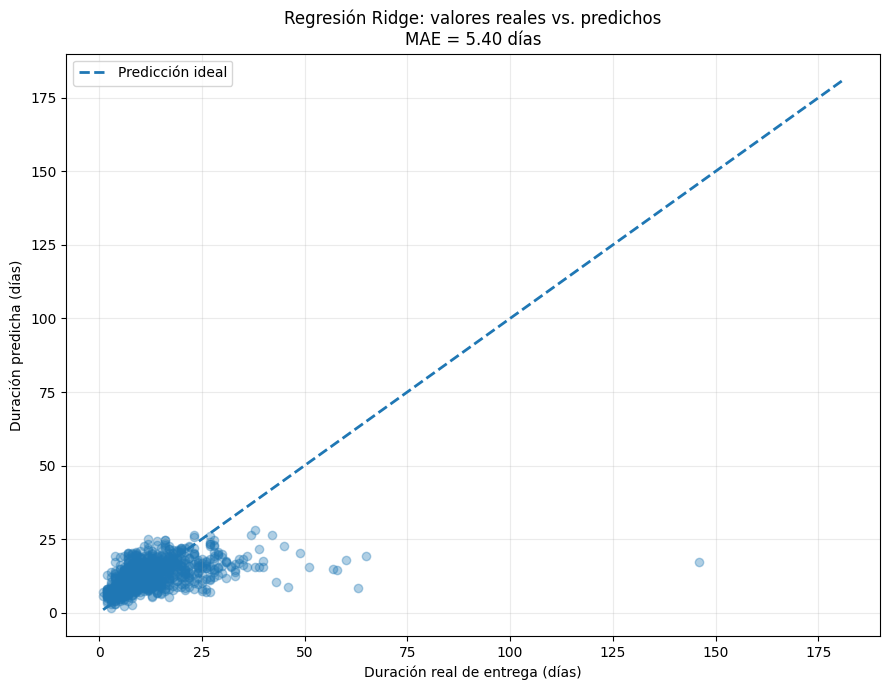

In [31]:

import matplotlib.pyplot as plt
import numpy as np

# Valores reales y predichos
reales = valid['dias_entrega'].to_numpy()
predichos = pred_dias

# Tomar una muestra para que la gráfica sea más legible
np.random.seed(1023)
n = min(1000, len(reales))
indices = np.random.choice(len(reales), n, replace=False)

plt.figure(figsize=(9, 7))

plt.scatter(
    reales[indices],
    predichos[indices],
    alpha=0.35
)

# Línea ideal: predicción igual al valor real
limite_min = min(reales.min(), predichos.min())
limite_max = max(reales.max(), predichos.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle='--',
    linewidth=2,
    label='Predicción ideal'
)

plt.xlabel('Duración real de entrega (días)')
plt.ylabel('Duración predicha (días)')
plt.title(f'Regresión Ridge: valores reales vs. predichos\nMAE = {mae:.2f} días')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Interpretación de la regresión Ridge**

El modelo de regresión Ridge obtuvo un error absoluto medio (MAE) de 5,4 días en el conjunto de validación. Esto significa que las predicciones de duración de entrega presentan una desviación absoluta promedio de 5,4 días respecto a los valores reales. Este resultado permite evaluar la precisión del modelo para estimar los tiempos de entrega, aunque sería conveniente compararlo con un modelo de referencia para determinar si ofrece una mejora significativa.

## 6. Interpretación de negocio

1. Compare la regresión logística con el modelo de referencia utilizando Accuracy, Recall y F1. Justifique su elección de `class_weight`.

Respuesta:La regresión logística sin balanceo obtuvo un Accuracy de 0,932, pero un Recall y un F1 de 0, mientras que el modelo de referencia predice la clase mayoritaria. El modelo con class_weight='balanced' obtuvo un Recall de 0,592 y un F1 de 0,189, por lo que logra detectar más pedidos tardíos. Aunque su Accuracy es menor (0,656), es más útil para identificar retrasos. Elegiría balanced como punto de partida porque detectar pedidos tardíos es importante para el negocio, aunque se deben considerar sus falsas alarmas y el costo total de los errores.

2. Analice qué tipo de pedidos presenta mayor error según los segmentos estudiados. ¿Cómo se relaciona esto con el costo de falsos positivos y falsos negativos?

Respuesta:Los errores deben analizarse por mes de compra y estado del cliente, comparando el porcentaje de error y la cantidad de pedidos de cada segmento. El modelo sin balanceo no detecta pedidos tardíos, por lo que genera falsos negativos. El modelo balanceado detecta más retrasos, pero produce más falsos positivos. Como cada falso positivo cuesta R$ 8 y cada falso negativo R$ 35, los falsos negativos tienen un impacto económico mayor por error. Sin embargo, en la validación, el modelo sin balanceo tuvo un costo de R$ 12.425 y el balanceado de R$ 18.355.

3. Proponga una mejora concreta para la semana 13. Considere la información del producto, del vendedor, del pago o el tratamiento de variables categóricas. Explique cómo verificará la mejora usando la misma partición de validación.

Respuesta:Para la semana 13, propongo mejorar las variables categóricas de producto, vendedor y tipo de pago, revisando sus categorías poco frecuentes y agrupándolas cuando sea apropiado. Mantendría el mismo preprocesamiento y la misma partición de entrenamiento y validación para comparar el modelo actual con el mejorado. Evaluaría Accuracy, Precision, Recall, F1, ROC-AUC, Average Precision y el costo empresarial. La mejora sería útil si aumenta la detección de pedidos tardíos o reduce el costo total sin empeorar significativamente las demás métricas.

## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [32]:
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)


Reporte: reports/S12_resultados_ID_23.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>